<a href="https://colab.research.google.com/github/ssevincc/signal-motif-classifier/blob/main/signal_motif_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42

In [ ]:
DATA_PATH = Path('signals_data.csv')
data = pd.read_csv(DATA_PATH)
display(data.head())

,signal_1,signal_2,signal_3,signal_4,signal_5,signal_6,signal_7,signal_8,signal_9,signal_10,...,signal_491,signal_492,signal_493,signal_494,signal_495,signal_496,signal_497,signal_498,signal_499,signal_500
0,121.18,120.86,119.54,121.72,105.38,122.54,120.39,118.70,119.83,118.31,...,113.13,123.76,119.10,121.48,120.79,118.12,117.29,118.75,110.25,118.07
1,122.01,121.16,119.45,122.39,100.30,123.18,119.40,118.82,120.09,118.05,...,110.72,124.64,119.11,121.59,120.63,117.70,116.99,118.28,109.33,117.31
2,123.49,121.59,119.23,123.49,93.45,124.04,116.96,119.10,120.61,117.69,...,106.33,125.98,119.28,121.81,120.34,117.10,116.46,117.46,109.03,115.95
3,125.28,121.93,118.81,124.65,89.32,124.63,112.99,119.51,121.36,117.51,...,100.53,127.25,119.71,122.14,119.86,116.62,115.57,116.51,110.39,114.21
4,126.92,122.00,118.17,125.52,90.31,124.70,108.80,119.92,122.18,117.81,...,93.85,128.18,120.24,122.60,118.90,116.30,114.00,115.77,112.66,112.26


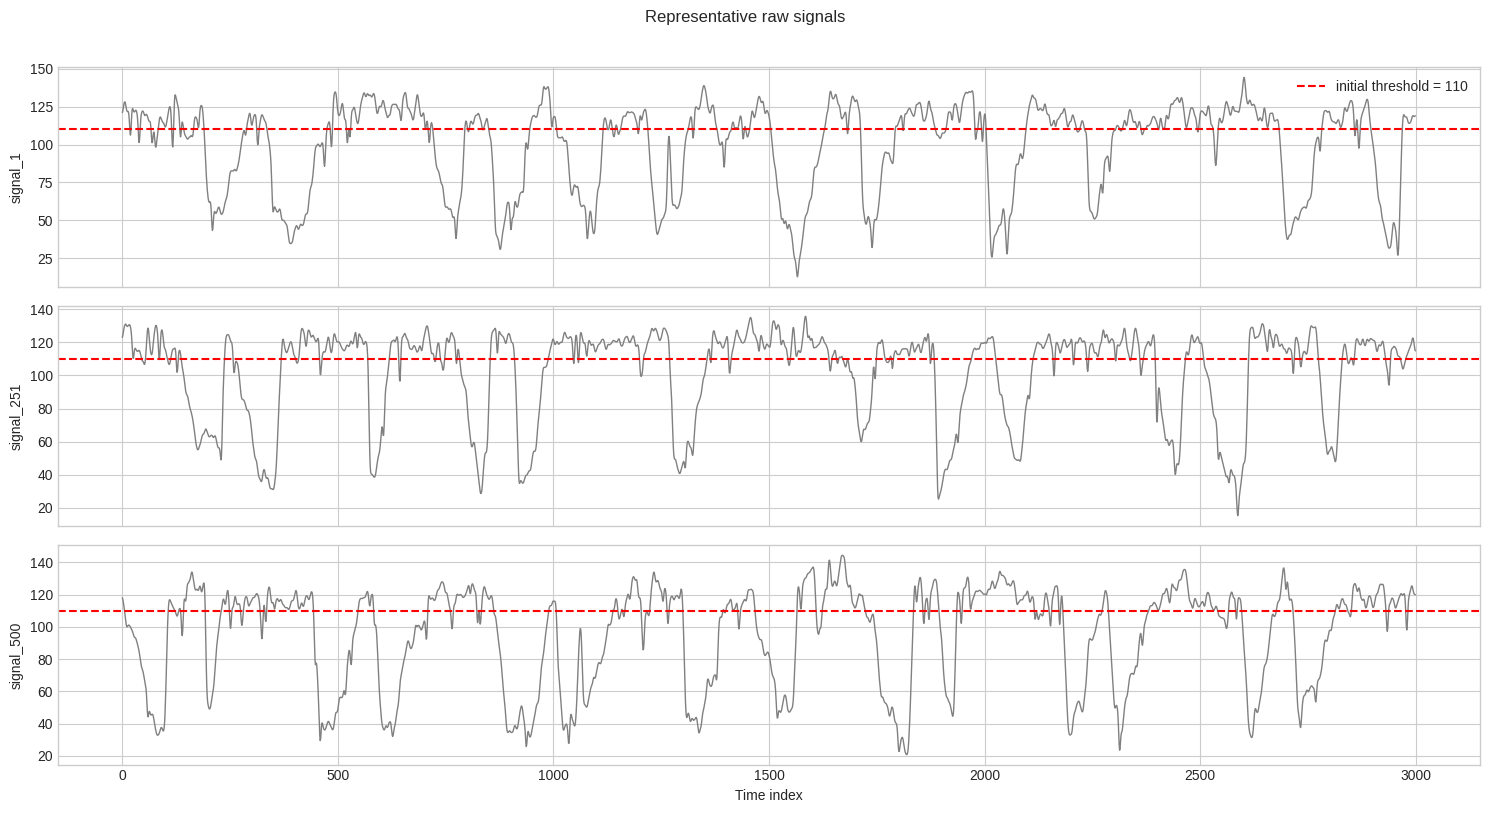

In [ ]:
example_names = [data.columns[0], data.columns[len(data.columns)//2], data.columns[-1]]
fig, axes = plt.subplots(len(example_names), 1, figsize=(15, 8), sharex=True)
for ax, name in zip(axes, example_names):
    ax.plot(data[name], lw=1, color='gray')
    ax.axhline(110, color='red', ls='--', label='initial threshold = 110')
    ax.set_ylabel(name)
axes[0].legend(loc='upper right')
axes[-1].set_xlabel('Time index')
fig.suptitle('Representative raw signals', y=1.01)
plt.tight_layout()

In [ ]:
ENTRY_THRESHOLD = 110.0
EXIT_THRESHOLD = 112.0
SMOOTH_WINDOW = 11
MIN_LENGTH = 8
MAX_GAP = 5
RESAMPLE_LENGTH = 96

def boolean_runs(mask):
    edges = np.diff(np.concatenate(([False], mask, [False])).astype(np.int8))
    starts = np.flatnonzero(edges == 1)
    ends = np.flatnonzero(edges == -1)
    return list(zip(starts, ends))

def detect_motifs(raw_signal):
    smooth = savgol_filter(raw_signal, window_length=SMOOTH_WINDOW, polyorder=2, mode='interp')

    active = False
    motif_mask = np.zeros(len(smooth), dtype=bool)
    for i, value in enumerate(smooth):
        if not active and value < ENTRY_THRESHOLD:
            active = True
        elif active and value > EXIT_THRESHOLD:
            active = False
        motif_mask[i] = active

    merged = []
    for start, end in boolean_runs(motif_mask):
        if merged and start - merged[-1][1] <= MAX_GAP:
            merged[-1][1] = end
        else:
            merged.append([start, end])

    intervals = [(start, end) for start, end in merged if end - start >= MIN_LENGTH]
    return smooth, intervals

def resample_and_normalize(segment):
    target_x = np.linspace(0, len(segment) - 1, RESAMPLE_LENGTH)
    resampled = np.interp(target_x, np.arange(len(segment)), segment)
    std = resampled.std()
    return (resampled - resampled.mean()) / (std if std > 1e-10 else 1.0)

In [ ]:
records, normalized_shapes = [], []
EDGE_CONTEXT = 4

for signal_id in data.columns:
    raw = data[signal_id].to_numpy(dtype=float)
    _, intervals = detect_motifs(raw)

    for start, end in intervals:
        left = max(0, start - EDGE_CONTEXT)
        right = min(len(raw), end + EDGE_CONTEXT)
        segment = raw[left:right]

        before = raw[max(0, left - 30):left]
        after = raw[right:min(len(raw), right + 30)]
        local_baseline = np.median(np.r_[before, after])
        if not np.isfinite(local_baseline):
            local_baseline = 120.0

        records.append({
            'signal_id': signal_id,
            'start': left,
            'end': right - 1,
            'length': right - left,
            'baseline': local_baseline,
            'min_value': segment.min(),
            'amplitude': local_baseline - segment.min(),
            'area_below_baseline': np.maximum(local_baseline - segment, 0).sum(),
        })
        normalized_shapes.append(resample_and_normalize(segment))

motifs = pd.DataFrame(records)
shapes = np.vstack(normalized_shapes)
print(f'Detected motifs: {len(motifs):,}')
display(motifs.head())

Detected motifs: 10,181


,signal_id,start,end,length,baseline,min_value,amplitude,area_below_baseline
0,signal_1,63,87,25,117.755,98.40,19.355,257.785
1,signal_1,130,169,40,117.675,103.63,14.045,354.450
2,signal_1,186,293,108,115.470,43.40,72.070,4043.310
3,signal_1,332,479,148,118.505,34.70,83.805,7407.930
4,signal_1,516,533,18,123.810,101.26,22.550,231.750


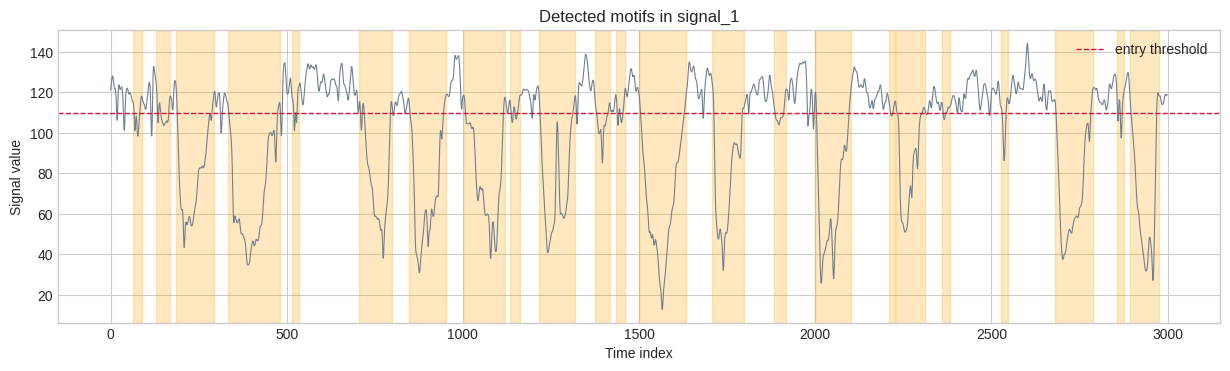

In [ ]:
# Visually validate extraction on one signal.
signal_to_plot = data.columns[0]
raw = data[signal_to_plot].to_numpy(float)
_, intervals = detect_motifs(raw)

plt.figure(figsize=(15, 3.8))
plt.plot(raw, color='slategray', lw=0.8)
plt.axhline(ENTRY_THRESHOLD, color='crimson', ls='--', lw=1, label='entry threshold')
for start, end in intervals:
    plt.axvspan(max(0, start - EDGE_CONTEXT), min(len(raw), end + EDGE_CONTEXT), color='orange', alpha=0.25)
plt.title(f'Detected motifs in {signal_to_plot}')
plt.xlabel('Time index'); plt.ylabel('Signal value'); plt.legend(); plt.show()

In [ ]:
pca = PCA(n_components=min(16, shapes.shape[1]), random_state=RANDOM_STATE)
shape_features = StandardScaler().fit_transform(pca.fit_transform(shapes))
duration_feature = StandardScaler().fit_transform(np.log1p(motifs[['length']]))

DURATION_WEIGHT = 0.75
features = np.column_stack([shape_features, DURATION_WEIGHT * duration_feature.ravel()])
print('Feature matrix:', features.shape)

Feature matrix: (10181, 17)


Silhouette scores: {2: np.float64(0.064), 3: np.float64(0.064), 4: np.float64(0.056), 5: np.float64(0.046), 6: np.float64(0.041), 7: np.float64(0.059), 8: np.float64(0.061), 9: np.float64(0.067), 10: np.float64(0.06)}
Chosen cluster count: 2


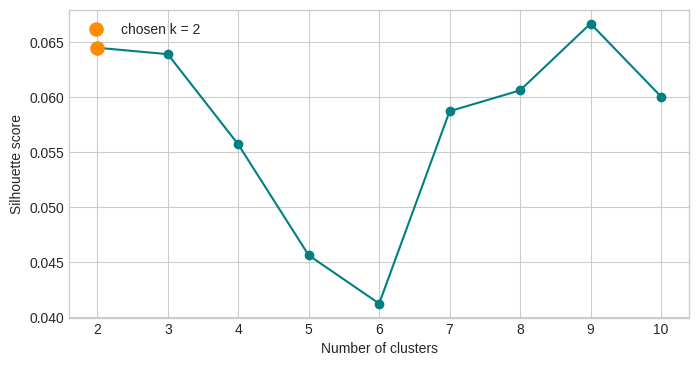

In [ ]:
candidate_k = range(2, 11)
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(features), size=min(1500, len(features)), replace=False)

scores = {}
for k in candidate_k:
    labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(features)
    scores[k] = silhouette_score(features[sample_idx], labels[sample_idx])

best_score = max(scores.values())
chosen_k = min(k for k, score in scores.items() if score >= 0.95 * best_score)
print('Silhouette scores:', {k: round(v, 3) for k, v in scores.items()})
print('Chosen cluster count:', chosen_k)

plt.figure(figsize=(8, 4))
plt.plot(list(scores), list(scores.values()), marker='o', color='teal')
plt.scatter([chosen_k], [scores[chosen_k]], color='darkorange', s=90, zorder=3, label=f'chosen k = {chosen_k}')
plt.xlabel('Number of clusters'); plt.ylabel('Silhouette score'); plt.legend(); plt.show()

In [ ]:
model = KMeans(n_clusters=chosen_k, n_init=30, random_state=RANDOM_STATE)
motifs['cluster'] = model.fit_predict(features) + 1

cluster_summary = (
    motifs.groupby('cluster')
    .agg(motifs=('cluster', 'size'),
         signals=('signal_id', 'nunique'),
         median_length=('length', 'median'),
         median_amplitude=('amplitude', 'median'),
         median_minimum=('min_value', 'median'))
    .reset_index()
)
display(cluster_summary)

,cluster,motifs,signals,median_length,median_amplitude,median_minimum
0,1,4087,500,19.0,18.3900,99.900
1,2,6094,500,93.0,78.7275,40.025


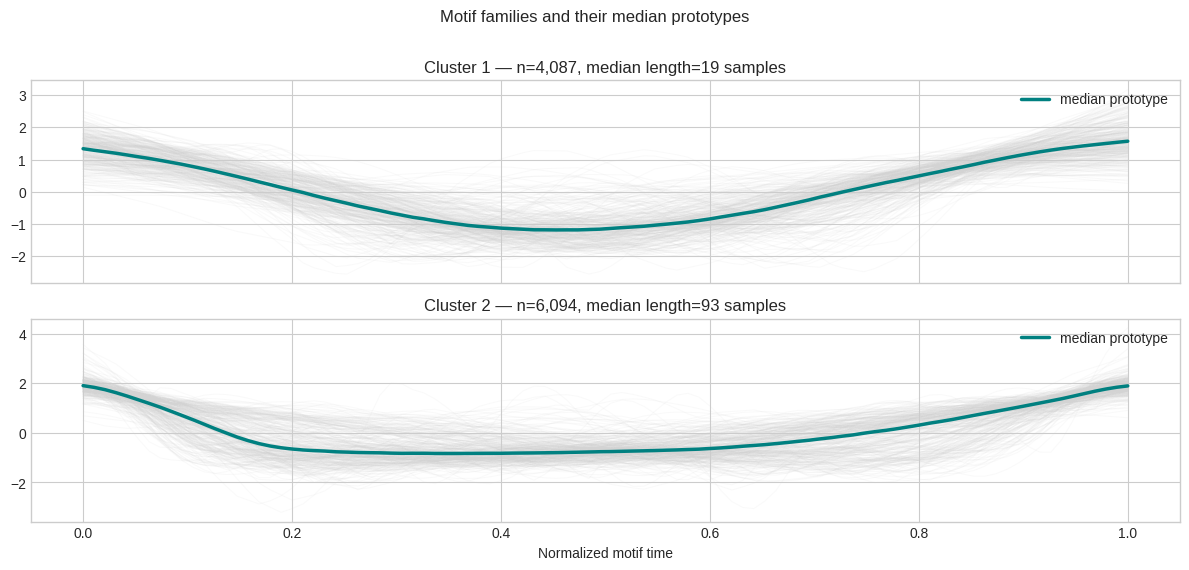

In [ ]:
# Plot every normalized motif in gray and each cluster's median prototype in color.
time = np.linspace(0, 1, RESAMPLE_LENGTH)
fig, axes = plt.subplots(chosen_k, 1, figsize=(12, 2.8 * chosen_k), sharex=True)
axes = np.atleast_1d(axes)
for cluster, ax in enumerate(axes, start=1):
    group = shapes[motifs['cluster'].to_numpy() == cluster]
    # Draw at most 300 members to keep the figure responsive.
    shown = group[:300]
    ax.plot(time, shown.T, color='lightgray', alpha=0.12, lw=0.7)
    ax.plot(time, np.median(group, axis=0), color='teal', lw=2.5, label='median prototype')
    median_length = motifs.loc[motifs.cluster == cluster, 'length'].median()
    ax.set_title(f'Cluster {cluster} — n={len(group):,}, median length={median_length:.0f} samples')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Normalized motif time')
fig.suptitle('Motif families and their median prototypes', y=1.01)
plt.tight_layout()

In [ ]:
OUTPUT_DIR = Path('motif_results')
OUTPUT_DIR.mkdir(exist_ok=True)
motifs.to_csv(OUTPUT_DIR / 'motif_assignments.csv', index=False)
cluster_summary.to_csv(OUTPUT_DIR / 'cluster_summary.csv', index=False)

prototype_table = pd.DataFrame({'normalized_time': time})
for cluster in range(1, chosen_k + 1):
    prototype_table[f'cluster_{cluster}_median'] = np.median(
        shapes[motifs['cluster'].to_numpy() == cluster], axis=0
    )
prototype_table.to_csv(OUTPUT_DIR / 'cluster_prototypes.csv', index=False)

print(f'Wrote results to: {OUTPUT_DIR.resolve()}')

Wrote results to: /content/motif_results
